# Bayyinah – Burnout Level Classification

In this notebook I build the classification model for Bayyinah. The goal is to predict an employee's `burnout_level`, which has four levels in order: Low, Moderate, High and Severe.

I try four models:

1. Decision Tree Induction
2. Bayesian Classification (Gaussian Naive Bayes)
3. Support Vector Machine (SVM)
4. Logistic Regression

After picking the best one, I use SHAP to explain its predictions.

The data was already cleaned and split in the data preparation notebook, so here I just load those files and use them as they are.

I run this notebook on Kaggle using Save Version → Save & Run All (Commit), so it keeps running even if I close the browser. Training takes around an hour (the SVM is the slow part), and if the SVM ends up being the chosen model, the SHAP part at the end can take another 2–4 hours.

## 1. Setup and loading

In [1]:
# the preprocessors were saved with scikit-learn 1.9.1, so I install the same version to load them without errors
# shap is for the explainability part at the end
!pip install -q scikit-learn==1.9.1 shap

In [2]:
import os, json, time, shutil, glob
import numpy as np
import pandas as pd
import sklearn
import joblib
import matplotlib.pyplot as plt
import shap

from scipy.stats import loguniform
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV, cross_validate, train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC
from sklearn.metrics import (f1_score, accuracy_score, cohen_kappa_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

RANDOM_STATE = 42
PREP_DIR = "/kaggle/input/datasets/voelasagreekgoddess/bayyinah/prepared"
MODELS_DIR = "models"
CLASS_ORDER = ["Low", "Moderate", "High", "Severe"]
LABEL_TO_INT = {"Low": 0, "Moderate": 1, "High": 2, "Severe": 3}

# I use the same 5 folds for all the models so the comparison is fair
CV = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

print("scikit-learn", sklearn.__version__, "| pandas", pd.__version__, "| numpy", np.__version__)

scikit-learn 1.9.1 | pandas 2.3.3 | numpy 2.1.3


Here I load the prepared files. The `if` part only matters if I ever run this on Colab instead of Kaggle: if the files aren't found, it asks me to upload the zip.

In [3]:
# only for Colab: upload the zip if the prepared files aren't there
if not os.path.exists(os.path.join(PREP_DIR, "X_train.csv")):
    from google.colab import files
    uploaded = files.upload()
    for name in uploaded:
        shutil.unpack_archive(name, "unzipped")
    os.makedirs(PREP_DIR, exist_ok=True)
    for path in glob.glob("unzipped/**/*", recursive=True):
        if os.path.isfile(path):
            shutil.copy(path, os.path.join(PREP_DIR, os.path.basename(path)))

with open(os.path.join(PREP_DIR, "feature_lists.json")) as f:
    FL = json.load(f)
FEATURE_LISTS = {"FULL": FL["FEATURES_FULL"], "HR": FL["FEATURES_HR"]}

X_train = pd.read_csv(os.path.join(PREP_DIR, "X_train.csv"))
X_test = pd.read_csv(os.path.join(PREP_DIR, "X_test.csv"))
y_train = pd.read_csv(os.path.join(PREP_DIR, "y_train_clf.csv"))["burnout_level"]
y_test = pd.read_csv(os.path.join(PREP_DIR, "y_test_clf.csv"))["burnout_level"]

# clone gives me an empty copy of the preprocessor, so every model fits its own one
PREPROCESSORS = {"FULL": clone(joblib.load(os.path.join(PREP_DIR, "preprocessor_full.pkl"))),
                 "HR": clone(joblib.load(os.path.join(PREP_DIR, "preprocessor_hr.pkl")))}

print("train:", X_train.shape, "| test:", X_test.shape)

train: (76804, 26) | test: (19202, 26)


## 2. Quick checks

Before training I want to be sure that no ID, leakage or target column slipped into X, that the columns are the ones I expect, and that there are no missing values.

I have two feature lists:
- FULL: all 26 features.
- HR: 22 features. It's FULL without sleep, exercise, therapy access and uses therapy, because a real HR system wouldn't know these things about an employee.

In [4]:
not_allowed = ["employee_id", "stress_score", "phq9_score", "phq9_category", "gad7_score", "gad7_category",
               "seeks_mental_health_support", "job_change_intention", "burnout_score", "burnout_level"]
assert not [c for c in not_allowed if c in X_train.columns]
assert X_train.columns.tolist() == FL["FEATURES_FULL"]
assert X_train.isna().sum().sum() == 0

# class percentages in the training set
print((y_train.value_counts(normalize=True) * 100).round(2).reindex(CLASS_ORDER))

burnout_level
Low         25.89
Moderate    26.31
High        19.26
Severe      28.54
Name: proportion, dtype: float64


## 3. How I train and evaluate the models

I put the preprocessor and the model together in one pipeline. This way, during cross-validation, the scaling is learned again inside each fold, and no information from the validation part leaks into training.

For each model I search for good settings with `RandomizedSearchCV` using 5-fold CV on the training set only, and I score with macro-F1. After that, I take the best settings and run 5-fold CV again on the whole training set. I use that number to compare the models, so they're all compared on the same folds and the same data. The test set isn't used for any of this.

The metrics I look at:
- macro-F1: my main metric. It treats the four levels equally, so the High class (the smallest one) counts as much as the others.
- accuracy
- QWK (quadratic weighted kappa): it punishes big mistakes more than small ones. Predicting Severe for a Low employee is a lot worse than predicting Moderate.
- far-off error %: the percentage of predictions that are two or more levels away from the real level.

In [5]:
results = []   # one row for every model + feature list
fitted = {}    # the final pipelines, trained on the whole training set

def tune(name, model, params, list_name, n_iter, search_data=None):
    feats = FEATURE_LISTS[list_name]
    pipe = Pipeline([("prep", clone(PREPROCESSORS[list_name])), ("model", model)])

    # search on the whole training set, or on a smaller sample if the model is too slow
    X_s, y_s = search_data if search_data is not None else (X_train, y_train)
    search = RandomizedSearchCV(pipe, params, n_iter=n_iter, scoring="f1_macro", cv=CV,
                                n_jobs=-1, random_state=RANDOM_STATE, refit=False)
    start = time.time()
    search.fit(X_s[feats], y_s)

    # run 5-fold CV with the best settings on the whole training set, then train the final model
    best_pipe = clone(pipe).set_params(**search.best_params_)
    cv = cross_validate(best_pipe, X_train[feats], y_train, cv=CV,
                        scoring=["f1_macro", "accuracy"], n_jobs=-1)
    best_pipe.fit(X_train[feats], y_train)
    minutes = (time.time() - start) / 60

    fitted[(name, list_name)] = best_pipe
    params_clean = {k.replace("model__", ""): (v.item() if hasattr(v, "item") else v)
                    for k, v in search.best_params_.items()}
    results.append({"model": name, "features": list_name,
                    "cv_macro_f1": cv["test_f1_macro"].mean(), "cv_macro_f1_std": cv["test_f1_macro"].std(),
                    "cv_accuracy": cv["test_accuracy"].mean(), "minutes": round(minutes, 1),
                    "best_params": params_clean})
    print(f"{name} ({list_name}): CV macro-F1 = {cv['test_f1_macro'].mean():.4f} | {minutes:.1f} min | {params_clean}")

# QWK and far-off error need the levels as numbers (Low=0 ... Severe=3)
def scores(y_true, y_pred):
    t = y_true.map(LABEL_TO_INT).values
    p = pd.Series(y_pred).map(LABEL_TO_INT).values
    return {"macro_f1": f1_score(y_true, y_pred, average="macro"),
            "accuracy": accuracy_score(y_true, y_pred),
            "qwk": cohen_kappa_score(t, p, weights="quadratic"),
            "far_off_%": np.mean(np.abs(t - p) >= 2) * 100}

## 4. Model 1: Decision Tree Induction

A decision tree keeps splitting the employees into smaller groups. At each step it picks the feature that separates the burnout levels the best. I let the search try both ways of measuring a good split: `gini` and `entropy` (information gain).

I also limit how deep the tree can go and how small a leaf can be. Without these limits the tree would basically memorize the training data and do badly on new employees.

In [6]:
dt_params = {"model__criterion": ["gini", "entropy"],
             "model__max_depth": [5, 8, 10, 12, 15, 20, None],
             "model__min_samples_leaf": [10, 20, 50, 100, 200],
             "model__class_weight": [None, "balanced"]}

for list_name in ["FULL", "HR"]:
    tune("Decision Tree", DecisionTreeClassifier(random_state=RANDOM_STATE), dt_params, list_name, n_iter=20)

Decision Tree (FULL): CV macro-F1 = 0.4805 | 1.1 min | {'min_samples_leaf': 20, 'max_depth': 10, 'criterion': 'gini', 'class_weight': 'balanced'}
Decision Tree (HR): CV macro-F1 = 0.4508 | 1.0 min | {'min_samples_leaf': 200, 'max_depth': None, 'criterion': 'gini', 'class_weight': 'balanced'}


## 5. Model 2: Bayesian Classification (Gaussian Naive Bayes)

Naive Bayes uses Bayes' theorem to calculate the probability of each burnout level based on the features. It's called "naive" because it assumes the features are independent of each other inside each class. The Gaussian version also assumes every feature is normally distributed inside each class.

The only thing I tune here is `var_smoothing`. It adds a small value to the variances so the model stays stable.

I don't expect this model to do very well on this data. A lot of the columns are one-hot (0 or 1), which aren't normally distributed, and some features are related to each other (seniority, meetings and salary, for example), so the independence assumption doesn't really hold. I still include it because it's a fast, simple probabilistic model and a good point of comparison.

In [7]:
nb_params = {"model__var_smoothing": loguniform(1e-12, 1e-1)}

for list_name in ["FULL", "HR"]:
    tune("Naive Bayes", GaussianNB(), nb_params, list_name, n_iter=20)

Naive Bayes (FULL): CV macro-F1 = 0.4318 | 0.5 min | {'var_smoothing': 0.04666683782217584}
Naive Bayes (HR): CV macro-F1 = 0.3878 | 0.5 min | {'var_smoothing': 0.04666683782217584}


## 6. Model 3: Support Vector Machine (SVM)

SVM tries to find the boundary that separates the classes with the widest possible margin. I use the RBF kernel, which lets the boundary be curved instead of a straight line. Since there are four classes, scikit-learn trains a separate SVM for every pair of classes and then combines their votes (one-vs-one).

The settings I tune:
- `C`: how strict the model is about misclassified points.
- `gamma`: how curvy the boundary is allowed to get.
- `class_weight`: whether to give smaller classes more weight.

The SVM is really slow on big data. Searching on all 76,804 rows would take hours, so for the SVM:
- the search runs on a stratified 15% sample of the training set (about 11,500 rows, all from train),
- then I check the best settings with 5-fold CV on the whole training set, same as the other models,
- and the final SVM is trained on the whole training set.

In [8]:
# 15% sample of the training set, keeping the same class percentages
X_sample, _, y_sample, _ = train_test_split(X_train, y_train, train_size=0.15,
                                            stratify=y_train, random_state=RANDOM_STATE)
print("SVM search sample:", X_sample.shape)

svm_params = {"model__C": [0.1, 0.5, 1, 5, 10],
              "model__gamma": ["scale", 0.005, 0.01, 0.02, 0.05],
              "model__class_weight": [None, "balanced"]}

for list_name in ["FULL", "HR"]:
    tune("SVM", SVC(kernel="rbf", random_state=RANDOM_STATE), svm_params, list_name,
         n_iter=12, search_data=(X_sample, y_sample))

SVM search sample: (11520, 26)
SVM (FULL): CV macro-F1 = 0.5768 | 45.5 min | {'gamma': 0.01, 'class_weight': 'balanced', 'C': 0.5}
SVM (HR): CV macro-F1 = 0.4957 | 60.4 min | {'gamma': 0.005, 'class_weight': 'balanced', 'C': 1}


## 6.1 Model 4: Logistic Regression

I also added Logistic Regression. Even though it has "regression" in its name, it's a classification model. It calculates a score for each burnout level, turns the scores into probabilities using softmax, and picks the level with the highest probability.

I added it because it's simple, fast and easy to explain. Every feature gets a coefficient that shows whether it pushes the prediction up or down, and by how much. I tune `C` (smaller C means a simpler model) and `class_weight`. It trains quickly, so I can search on the whole training set.

In [9]:
from sklearn.linear_model import LogisticRegression

lr_params = {"model__C": loguniform(1e-3, 1e2),
             "model__class_weight": [None, "balanced"]}

for list_name in ["FULL", "HR"]:
    tune("Logistic Regression", LogisticRegression(max_iter=3000, random_state=RANDOM_STATE),
         lr_params, list_name, n_iter=20)

Logistic Regression (FULL): CV macro-F1 = 0.5752 | 1.4 min | {'C': 3.4702669886504163, 'class_weight': 'balanced'}
Logistic Regression (HR): CV macro-F1 = 0.4927 | 1.2 min | {'C': 0.04661686413912769, 'class_weight': 'balanced'}


## 7. Comparing the models and choosing one

I choose the final model based only on the CV results from the training set. The model with the highest CV macro-F1 on the FULL list is chosen, and I use the same model for the HR list too.

In [10]:
cv_table = pd.DataFrame(results).sort_values(["features", "cv_macro_f1"], ascending=[True, False])
display(cv_table.round(4).reset_index(drop=True))

full_only = cv_table[cv_table["features"] == "FULL"]
CHOSEN = full_only.sort_values("cv_macro_f1", ascending=False)["model"].iloc[0]
print("Chosen model (by CV macro-F1):", CHOSEN)

,model,features,cv_macro_f1,cv_macro_f1_std,cv_accuracy,minutes,best_params
0,SVM,FULL,0.5768,0.0025,0.5871,45.5,"{'gamma': 0.01, 'class_weight': 'balanced', 'C..."
1,Logistic Regression,FULL,0.5752,0.0048,0.5884,1.4,"{'C': 3.4702669886504163, 'class_weight': 'bal..."
2,Decision Tree,FULL,0.4805,0.0044,0.4882,1.1,"{'min_samples_leaf': 20, 'max_depth': 10, 'cri..."
3,Naive Bayes,FULL,0.4318,0.0031,0.5084,0.5,{'var_smoothing': 0.04666683782217584}
4,SVM,HR,0.4957,0.0025,0.5110,60.4,"{'gamma': 0.005, 'class_weight': 'balanced', '..."
5,Logistic Regression,HR,0.4927,0.0030,0.5130,1.2,"{'C': 0.04661686413912769, 'class_weight': 'ba..."
6,Decision Tree,HR,0.4508,0.0039,0.4678,1.0,"{'min_samples_leaf': 200, 'max_depth': None, '..."
7,Naive Bayes,HR,0.3878,0.0013,0.4680,0.5,{'var_smoothing': 0.04666683782217584}


Chosen model (by CV macro-F1): SVM


## 8. Results on the test set

This is the first time I touch the test set. I show the results of all the models so everything is transparent, but the model was already chosen in the previous step using CV only.

In [11]:
test_rows = []
test_preds = {}
for (name, list_name), pipe in fitted.items():
    pred = pipe.predict(X_test[FEATURE_LISTS[list_name]])
    test_preds[(name, list_name)] = pred
    test_rows.append({"model": name, "features": list_name, **scores(y_test, pred)})

test_table = pd.DataFrame(test_rows).sort_values(["features", "macro_f1"], ascending=[True, False])
display(test_table.round(4).reset_index(drop=True))

,model,features,macro_f1,accuracy,qwk,far_off_%
0,SVM,FULL,0.5815,0.5912,0.7831,4.9839
1,Logistic Regression,FULL,0.5811,0.5939,0.7851,5.1297
2,Decision Tree,FULL,0.4813,0.4864,0.6516,11.2124
3,Naive Bayes,FULL,0.4289,0.5078,0.6237,17.1649
4,SVM,HR,0.4922,0.5062,0.6714,11.1186
5,Logistic Regression,HR,0.4883,0.5082,0.6701,11.6707
6,Decision Tree,HR,0.4514,0.4665,0.5892,15.4776
7,Naive Bayes,HR,0.3863,0.4668,0.5413,21.9404


### Classification report and confusion matrix for the chosen model

The matrix on the left shows the counts. The one on the right is normalized by row, so each row shows how the employees of that real level were predicted. Most mistakes should be next to the diagonal, meaning the model was off by one level.

===== SVM (FULL) – test set =====
              precision    recall  f1-score   support

         Low      0.723     0.719     0.721      4971
    Moderate      0.477     0.437     0.456      5051
        High      0.363     0.463     0.407      3699
      Severe      0.783     0.705     0.742      5481

    accuracy                          0.591     19202
   macro avg      0.587     0.581     0.582     19202
weighted avg      0.606     0.591     0.597     19202



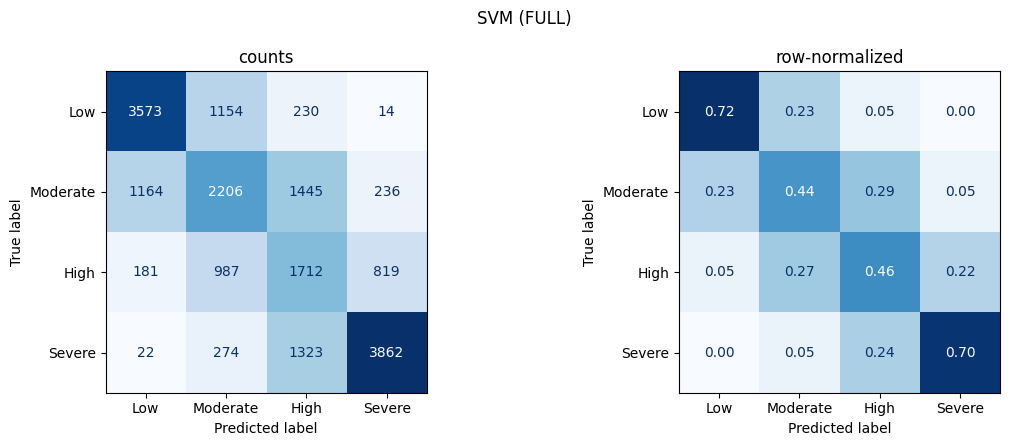

===== SVM (HR) – test set =====
              precision    recall  f1-score   support

         Low      0.612     0.649     0.630      4971
    Moderate      0.391     0.330     0.358      5051
        High      0.294     0.358     0.323      3699
      Severe      0.678     0.639     0.658      5481

    accuracy                          0.506     19202
   macro avg      0.494     0.494     0.492     19202
weighted avg      0.511     0.506     0.507     19202



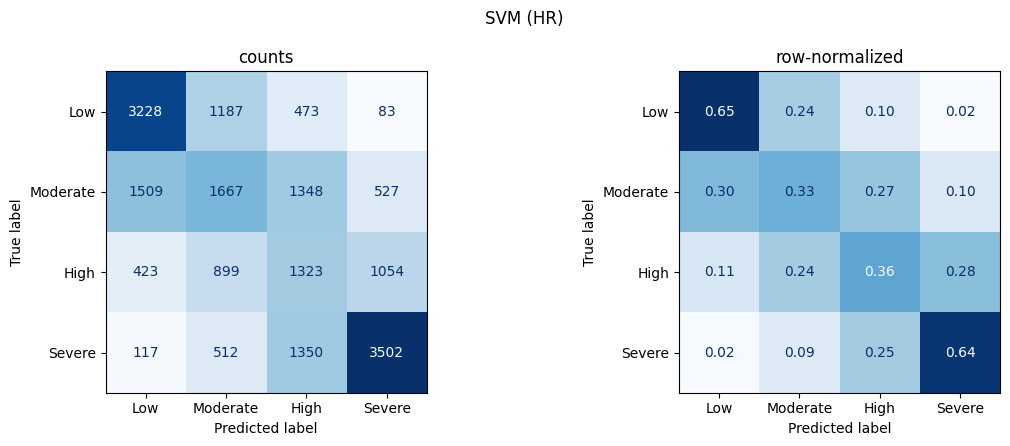

In [12]:
for list_name in ["FULL", "HR"]:
    pred = test_preds[(CHOSEN, list_name)]
    print(f"===== {CHOSEN} ({list_name}) – test set =====")
    print(classification_report(y_test, pred, labels=CLASS_ORDER, digits=3))

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    for ax, norm, title in [(axes[0], None, "counts"), (axes[1], "true", "row-normalized")]:
        cm = confusion_matrix(y_test, pred, labels=CLASS_ORDER, normalize=norm)
        ConfusionMatrixDisplay(cm, display_labels=CLASS_ORDER).plot(
            ax=ax, cmap="Blues", colorbar=False, values_format=".2f" if norm else "d")
        ax.set_title(title)
    fig.suptitle(f"{CHOSEN} ({list_name})")
    plt.tight_layout()
    plt.show()

## 9. Saving the model

I save the chosen model for both feature lists. Each saved file is the full pipeline (preprocessor + model) trained on the whole training set, so the backend can give it raw employee data directly. I also save the CV and test tables in one CSV file.

I save everything before the SHAP part on purpose. SHAP takes a long time, so if anything goes wrong there, the models are already saved.

In [13]:
os.makedirs(MODELS_DIR, exist_ok=True)
for list_name in ["FULL", "HR"]:
    path = os.path.join(MODELS_DIR, f"burnout_classifier_{list_name.lower()}.pkl")
    joblib.dump(fitted[(CHOSEN, list_name)], path)
    print("saved", path)

all_results = pd.concat([cv_table.assign(evaluated_on="5-fold CV (train)"),
                         test_table.assign(evaluated_on="test set")], ignore_index=True)
all_results.to_csv(os.path.join(MODELS_DIR, "classification_results.csv"), index=False)

# zip the models folder so it's easy to download
shutil.make_archive("bayyinah_models", "zip", MODELS_DIR)
try:
    from google.colab import files
    files.download("bayyinah_models.zip")
except ImportError:
    print("not in Colab, files are in the models folder")

saved models/burnout_classifier_full.pkl
saved models/burnout_classifier_hr.pkl


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10. Explaining the chosen model with SHAP

Explainability is an important part of Bayyinah, so I use SHAP on the model that was actually chosen in section 7, whichever one it is.

SHAP tells me how much each feature pushed a prediction towards a certain burnout level. I use `KernelExplainer` because it works with any model, including the SVM. The downside is that it's slow, because it has to run the model many times for every single employee. To keep the running time reasonable I:
- explain 200 random employees from the test set,
- use 10 "typical" employees as the background (I take 2,000 training employees and summarize them with k-means),
- set `nsamples=1000` for each employee.

If the chosen model is the SVM, this part can take around 2–4 hours. There's a progress bar to follow it.

What SHAP explains here depends on the model. If the model gives probabilities (like Logistic Regression), SHAP explains the probability of each level. The SVM doesn't give probabilities, so in that case SHAP explains the SVM's score for each level (a higher score means that level is more likely).

The plot is for the Severe class. Every dot is one employee:
- a dot on the right means that feature pushed the employee towards Severe,
- red means the feature value was high and blue means it was low.

The numbers were scaled, so "high" just means above average.

One thing to keep in mind: the data is synthetic, so this shows how the dataset was generated, not proven real-life causes of burnout.

  0%|          | 0/200 [00:00<?, ?it/s]

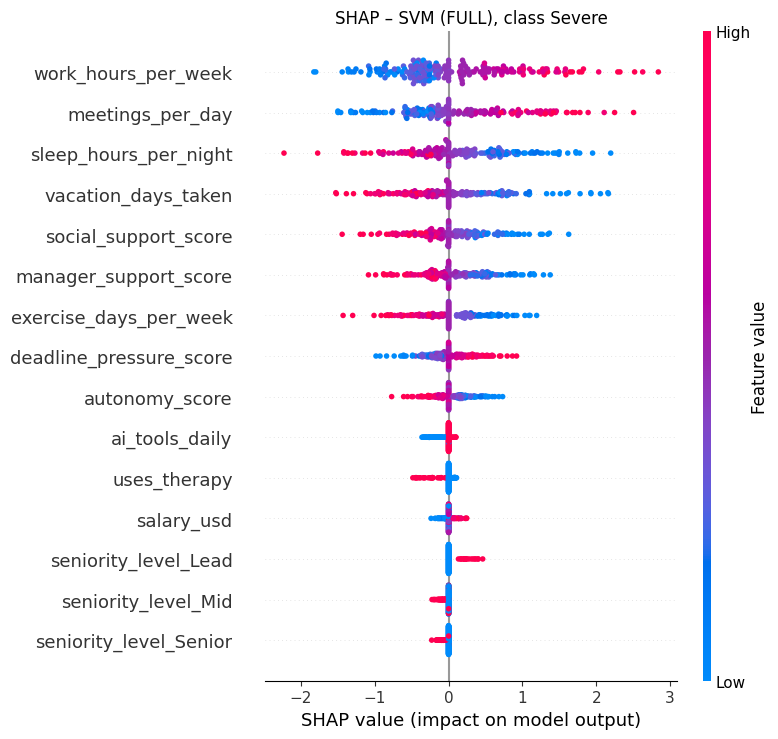

In [14]:
best_pipe = fitted[(CHOSEN, "FULL")]
prep = best_pipe.named_steps["prep"]
best_model = best_pipe.named_steps["model"]

# feature names after preprocessing, I remove the "num__" / "cat__" part so they're easier to read
feature_names = [name.split("__", 1)[1] for name in prep.get_feature_names_out()]

# background: 2,000 training employees summarized into 10 typical ones
background = shap.kmeans(prep.transform(X_train[FEATURE_LISTS["FULL"]].sample(2000, random_state=RANDOM_STATE)), 10)

# the 200 test employees I want to explain
X_explain = pd.DataFrame(prep.transform(X_test[FEATURE_LISTS["FULL"]].sample(200, random_state=RANDOM_STATE)),
                         columns=feature_names)

# probabilities if the model has them, otherwise the decision score (this is the case for the SVM)
if hasattr(best_model, "predict_proba"):
    model_output = best_model.predict_proba
else:
    model_output = best_model.decision_function

explainer = shap.KernelExplainer(model_output, background)
shap_values = explainer.shap_values(X_explain, nsamples=1000)

# get the SHAP values for the Severe class
# (depending on the shap version, the result is either a list with one array per class or one 3D array)
severe = list(best_model.classes_).index("Severe")
if isinstance(shap_values, list):
    severe_values = shap_values[severe]
else:
    severe_values = shap_values[:, :, severe]

shap.summary_plot(severe_values, X_explain, max_display=15, show=False)
plt.title(f"SHAP – {CHOSEN} (FULL), class Severe")
plt.tight_layout()
plt.show()